# Revenant Conduit (Harakim)

Revenant Conduit is a toggled self buff. While it is open, the caster's Ghost Companion skill
counts as 30–150% higher when companions are statted. Existing companions are re-statted
immediately. Every point of post-mitigation damage a companion deals also heals the (player)
owner for 10–50% of it. The conduit drains 1 endurance per second and closes when endurance runs
out, when it expires after 360 s, or when the caster recasts it.

| | |
|---|---|
| Class | Harakim |
| Target | Self (affects owned ghost companions) |
| Cost | 17 mana (not divided by 3 for Harakim); needs at least 25 endurance but does not spend it |
| Upkeep | 1 endurance per second while open |
| Cooldown | none; recasting while open closes it (toggle) |
| Landing roll | none |
| Duration | 360 s, or until endurance reaches 0, the caster recasts it, or no companion is left |
| Effect | `boost = clamp(⌊p/10⌋·30, 30, 150)` %; companions are statted from `ghost·(100+boost)/100`; owner healed `clamp(⌊boost/3⌋, 0, 50)` % of companion damage |
| Source | `server/src/driver/skill/companion.rs::skill_revenant_conduit`, `recompute_companion_stats`; drain and heal in `server/src/state/stats.rs` (`apply_revenant_conduit_heal`) |

---

# Formula

With $p$ the modified Revenant Conduit skill and $g$ the modified Ghost Companion skill:

$$
\text{boost} = \operatorname{clamp}\!\left(30\lfloor p/10 \rfloor,\ 30,\ 150\right)\%
\qquad
\text{heal} = \operatorname{clamp}\!\left(\lfloor \text{boost}/3 \rfloor,\ 0,\ 50\right)\%
$$

$$
g' = \left\lfloor \frac{g\,(100 + \text{boost})}{100} \right\rfloor
\qquad
\text{base} = \text{race}\!\left(\left\lfloor \tfrac{4g'}{11} \right\rfloor\right)
\qquad
\text{attribute} = \max\!\left(10,\ \min\!\left(\text{cap},\ \left\lfloor \tfrac{3\,\text{base}}{\text{attrib}[3]} \right\rfloor\right)\right)
\qquad
\text{HP} = \max(50,\ \min(\text{cap},\ 5\,\text{base}))
$$

Skills follow the attribute rule with the template's `skill[n][3]` divisor. The template caps
(`attrib[n][2]`, `skill[n][2]`, `hp[2]`) come from the `CT_COMPANION` template in the world
snapshot, so this notebook models the **uncapped** values with divisor 1, as the Rust test does.

| Quantity | Breakpoint |
|---|---|
| Boost and heal ceiling | +150% and 50% from $p \ge 50$, well below the raise caps |
| Steps | +30% / +10% heal per 10 skill points |
| Upkeep | 360 endurance for a full 360 s, plus 17 mana |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
MANA_COST = 17
END_GATE = 25
DURATION_S = 360
GHOST_SWEEP = (50, 80, 105, 120)

# Model

In [2]:
def boost_pct(p):
    return mm.clamp(mm.idiv(p, 10) * 10 * 3, 30, 150)


def heal_pct(p):
    return mm.clamp(mm.idiv(boost_pct(p), 3), 0, 50)


def companion_base(ghost, boost=0, race="Harakim"):
    eff = np.asarray(ghost) * (100 + np.asarray(boost)) // 100
    return mm.spell_race_mod(mm.idiv(eff * 4, 11), race)


def companion_attrib(base, divisor=1):
    return np.maximum(10, mm.idiv(np.asarray(base) * 3, divisor))


def companion_hp(base):
    return np.maximum(50, np.asarray(base) * 5)


def heal_hp(companion_damage_hp, p):
    """HP the owner regains for `companion_damage_hp` HP of post-mitigation companion damage."""
    return np.asarray(companion_damage_hp) * heal_pct(p) / 100

# Validation

- `revenant_conduit_boosts_existing_companions_and_toggles_off`: skill 20 → boost 60, mana
  50,000 → 33,000, endurance unchanged; recasting removes the item.
- `revenant_conduit_boost_is_clamped`: skill 5 → 30, skill 200 → 150.
- `revenant_conduit_requires_endurance`: 24,000 endurance is refused.
- `restat_owned_companions_scales_stats_from_ghost_skill` (Ghost 110): base 40 → attributes 120,
  HP and endurance 200, mana 0. With the conduit at skill 20 (+60%): 176 → base 64 → attributes 192.
- `revenant_conduit_heals_owner_by_scaled_damage_percentage`: boost 30 heals 2,000 of 20,000;
  boost 150 heals 10,000.

In [3]:
assert boost_pct(20) == 60 and boost_pct(5) == 30 and boost_pct(200) == 150
assert 50_000 - MANA_COST * 1000 == 33_000 and 24_000 < END_GATE * 1000
assert companion_base(110) == 40 and companion_attrib(40) == 120 and companion_hp(40) == 200
assert companion_base(110, 60) == 64 and companion_attrib(64) == 192
assert mm.idiv(20_000 * mm.clamp(mm.idiv(30, 3), 0, 50), 100) == 2_000
assert mm.idiv(20_000 * mm.clamp(mm.idiv(150, 3), 0, 50), 100) == 10_000
assert boost_pct(49) == 120 and boost_pct(50) == 150 and heal_pct(50) == 50
print("Revenant Conduit model OK")

Revenant Conduit model OK


# Plots

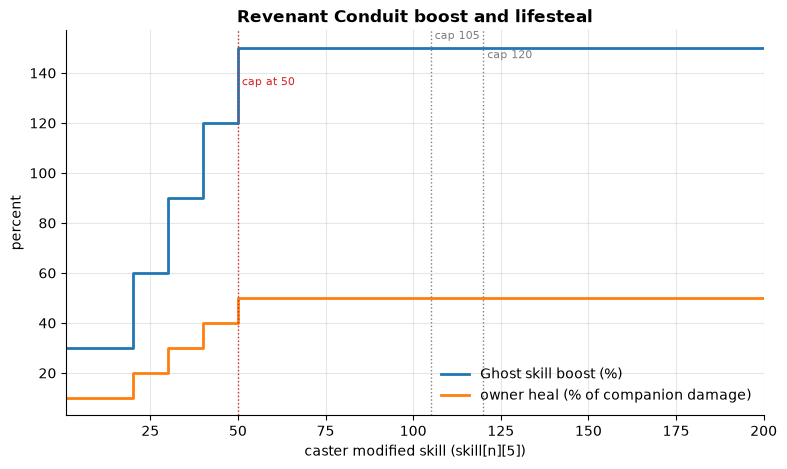

In [4]:
fig, ax = plt.subplots()
ax.step(P, boost_pct(P), where="post", label="Ghost skill boost (%)")
ax.step(P, heal_pct(P), where="post", label="owner heal (% of companion damage)")
mm.skill_axis(ax, "percent", "Revenant Conduit boost and lifesteal")
mm.mark_caps(ax, extra=[(50, "cap at 50")])
ax.legend()

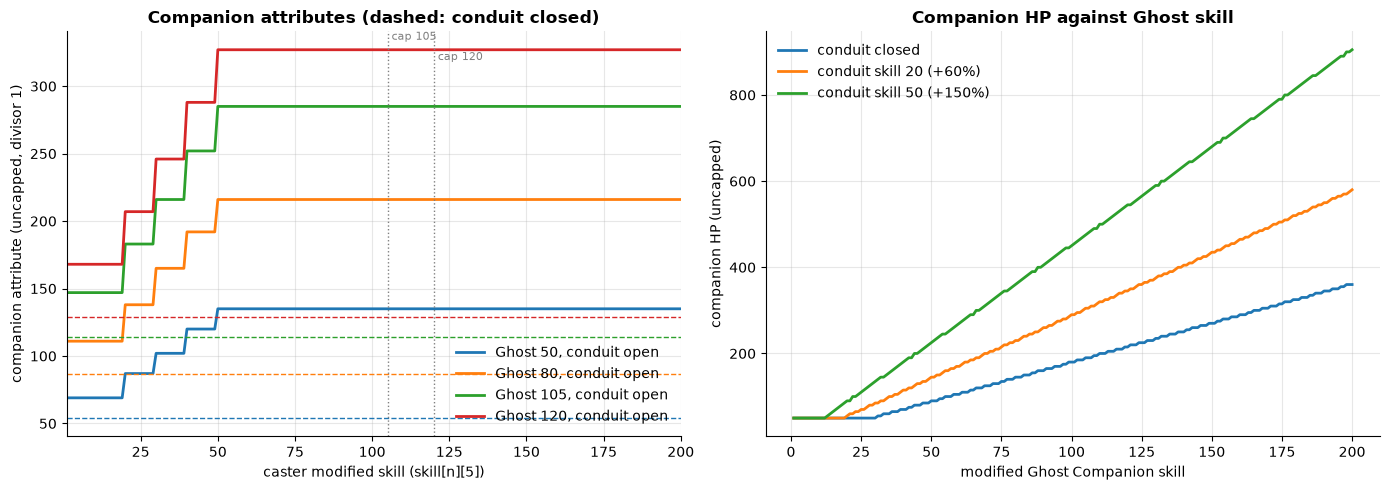

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for g in GHOST_SWEEP:
    line, = ax.plot(P, companion_attrib(companion_base(g, boost_pct(P))), label=f"Ghost {g}, conduit open")
    ax.axhline(companion_attrib(companion_base(g)), color=line.get_color(), ls="--", lw=1)
mm.skill_axis(ax, "companion attribute (uncapped, divisor 1)", "Companion attributes (dashed: conduit closed)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
G = np.arange(1, 201)
for p in (0, 20, 50):
    label = "conduit closed" if p == 0 else f"conduit skill {p} (+{int(boost_pct(p))}%)"
    b = companion_base(G) if p == 0 else companion_base(G, boost_pct(p))
    ax.plot(G, companion_hp(b), label=label)
ax.set_xlabel("modified Ghost Companion skill")
ax.set_ylabel("companion HP (uncapped)")
ax.set_title("Companion HP against Ghost skill")
ax.legend()
plt.tight_layout()

# Observations

- **Saturates at skill 50.** The boost moves in +30% steps every 10 points (skill 1–19 already
  gives +30%) and reaches +150% / 50% lifesteal at skill 50. Every point above 50, including the
  whole range up to the raise caps, does nothing.
- **×2.5 companion.** With Ghost 105 the companion's base goes from 38 to 95: attributes 114 → 285
  and HP 190 → 475 (uncapped). With Ghost 120 it is 129 → 327 and 215 → 545. The template caps
  (`attrib[n][2]`, `skill[n][2]`, `hp[2]`) may cut this down. They live in the world snapshot,
  so check them before tuning: if they sit near the closed-conduit values, most of the boost is
  wasted, and the lifesteal is the only part that matters.
- **50% lifesteal on someone else's damage.** Every HP a companion removes after armor heals the
  owner for half of it, with no cap other than the owner's max HP. A second companion (Kindred
  Spirit) doubles the healing. Only player owners are healed.
- **Very cheap upkeep.** 17 mana opens it for up to 360 s; the only ongoing cost is 1 endurance
  per second (360 in total). The 25-endurance gate is checked but never spent. The talent text
  ("at the cost of mana and a steady endurance drain") matches this.
- **Toggling is free in both directions.** Closing it costs nothing and needs no endurance, and
  re-opening costs 17 mana with no cooldown. Companions are re-statted on every toggle, so the
  boost applies to ghosts that are already summoned.
- **It closes itself when the pack is gone.** `clear_companion_dependent_buffs` removes it when the
  owner has no living companion, so a dead ghost forces a resummon (45 mana) and a recast.
- **Balance suggestions.** Spread the curve over the full skill range, for example
  `boost = clamp(p + p/2, 30, 150)` (+150% at 100) and `heal = clamp(p/4, 5, 30)` (26% at 105).
  Consider a drain that scales with the number of companions, so Kindred Spirit does not double
  the lifesteal for free.